# HUD con un HOE en el parabrisas (Optiland)

Simulamos el arreglo que teníamos pensado y vemos **cómo se ve una imagen** a través de él.

```
                    ● imagen virtual (1.2 m detrás del vidrio)
                    ┊
 ══════════════ vidrio exterior 3 mm ══════════════
 ────────────── PVB 0.76 mm  (HOE en medio) ───────
 ══════════════ vidrio interior 3 mm ══════════════
          ↑ ↓                 ↖
          ↑ ↓  0.8 m             ↖  400 mm, a 45°
          ↑ ↓                       ↖
       conductor                       ▭ proyector
```

**Plan**
1. Parámetros.
2. **Cómo se construye el HOE** (y por qué funciona como lente).
3. **El arreglo en Optiland**, superficie por superficie.
4. La imagen de prueba en el proyector.
5. **Lo que ve el conductor.**
6. Vista 3D.

## 0. Preparación

In [83]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import map_coordinates
import optiland.backend as be
from optiland.optic import Optic
from optiland.materials import IdealMaterial
from optiland.phase.base import BasePhaseProfile

warnings.filterwarnings('ignore', message='paraxial ray tracing')   # aviso de Optiland que aquí no aplica

## 1. Parámetros

Todo en **mm**, λ en **µm**, ángulos en **grados**.

In [84]:
# ---------- ARREGLO ----------
LAM      = 0.532            # λ del proyector (verde) [µm]
D_PROY   = 400.0            # proyector -> HOE
ANG      = 45.0             # el proyector llega a 45° desde abajo
D_IMG    = 1200.0           # imagen virtual detrás del HOE
D_OJO    = 800.0            # HOE -> ojo

# ---------- PARABRISAS ----------
T_VIDRIO = 3.0              # grosor de cada vidrio
T_PVB    = 0.76             # grosor del PVB (el HOE va en medio)
VIDRIO   = IdealMaterial(n=1.518)
PVB      = IdealMaterial(n=1.479)

# ---------- OJO ----------
PUPILA   = 4.0              # diámetro de la pupila
ENFOQUE  = D_OJO + D_IMG    # el ojo enfoca a 2 m, donde debería estar la imagen

# ---------- IMAGEN DE PRUEBA ----------
IMAGEN          = 'WhatsApp Image 2026-10-22 at 7.18.21 PM.jpeg'  # cualquier imagen de la carpeta
ANCHO_PANTALLA  = 120.0                   # ancho de la pantalla del proyector [mm]

A = np.radians(ANG)

### El color de la luz

Todo el notebook usa **una sola longitud de onda**, `LAM`: el proyector emite solo ese color, así que **no hay aberración cromática**. Para que las imágenes se vean como las vería el conductor, se pintan del color de esa λ: negro = sin luz y el color de `LAM` = luz al máximo.

`color_de_lambda` da el color RGB aproximado de una λ visible (380–780 nm). Si cambias `LAM`, el color cambia solo.

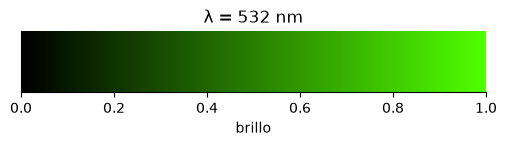

In [85]:
from matplotlib.colors import LinearSegmentedColormap


def color_de_lambda(lam_um):
    """Color RGB (de 0 a 1) aproximado de una luz de longitud de onda lam_um [µm]."""
    w = lam_um * 1000                                   # µm -> nm
    if w < 440:
        r, g, b = (440 - w) / 60, 0.0, 1.0              # violeta
    elif w < 490:
        r, g, b = 0.0, (w - 440) / 50, 1.0              # azul
    elif w < 510:
        r, g, b = 0.0, 1.0, (510 - w) / 20             # cian
    elif w < 580:
        r, g, b = (w - 510) / 70, 1.0, 0.0             # verde -> amarillo
    elif w < 645:
        r, g, b = 1.0, (645 - w) / 65, 0.0             # naranja
    else:
        r, g, b = 1.0, 0.0, 0.0                         # rojo
    return np.clip([r, g, b], 0, 1)


COLOR_LAM = color_de_lambda(LAM)
MAPA_LAM = LinearSegmentedColormap.from_list('lam', ['black', COLOR_LAM])   # negro -> color de LAM

plt.figure(figsize=(6, 0.8))
plt.imshow(np.linspace(0, 1, 256)[None, :], cmap=MAPA_LAM, aspect='auto', extent=[0, 1, 0, 1])
plt.yticks([]); plt.xlabel('brillo'); plt.title(f'λ = {LAM * 1000:.0f} nm')
plt.show()

## 2. Cómo se construye el HOE

### Grabarlo
El HOE es una película delgada de fotopolímero (~16 µm) dentro del PVB. Para grabarlo se ilumina con **dos ondas a la vez**:
- **R** (referencia): sale de donde va a estar el **proyector**;
- **O** (objeto): sale del punto donde queremos la **imagen virtual**.

Las dos interfieren y la película guarda las **franjas**, es decir, la diferencia de sus fases:

$$\varphi_H(x,y) = \varphi_O(x,y) - \varphi_R(x,y)$$

### Leerlo
Cuando después lo ilumina el proyector (la onda R), el HOE **reconstruye la onda O**: la luz sale como si viniera de la imagen virtual. En rayos, cada rayo se desvía según la **pendiente de la fase**:

$$\mathbf k_{sal,\parallel} = \mathbf k_{ent,\parallel} + \nabla\varphi_H$$

Eso es justo lo que hace Optiland con una superficie de fase (`phase_profile`).

### La versión simple: lente + rejilla
Si desarrollas $\varphi_O - \varphi_R$ cerca del centro del HOE, quedan dos términos:

$$\varphi_H \approx \underbrace{-k\,\sin 45°\; y}_{\text{rejilla: dobla la luz } 45°} \;\underbrace{-\;\frac{k\,(x^2+y^2)}{2f}}_{\text{lente}} ,\qquad \frac1f = \frac1{400} - \frac1{1200}\;\Rightarrow\; f = 600\text{ mm}$$

- La **rejilla** (una rampa de fase) desvía la luz del proyector, que llega a 45°, hacia el conductor.
- La **lente** funciona como un espejo cóncavo de f = 600 mm: el proyector a 400 mm queda como una imagen virtual a 1200 mm, **3 veces más grande**.

Usamos esta versión simple. Es la ecuación de "lente + rampa" del reporte.

In [86]:
k = 2 * np.pi / (LAM * 1e-3)                 # número de onda [rad/mm]
F_HOE = 1 / (1 / D_PROY - 1 / D_IMG)
print(f'focal del HOE: f = {F_HOE:.0f} mm    aumento: {D_IMG / D_PROY:.1f}x')
print(f'franjas en el centro: cada {LAM / np.sin(A) * 1000:.0f} nm')

focal del HOE: f = 600 mm    aumento: 3.0x
franjas en el centro: cada 752 nm


Para dárselo a Optiland se escribe una clase hija de `BasePhaseProfile` (la base de todas las superficies de fase) con tres métodos:
- `get_phase`: la fase φ(x, y);
- `get_gradient`: su gradiente (∂φ/∂x, ∂φ/∂y, 0), que es lo que dobla los rayos;
- `get_paraxial_gradient`: ∂φ/∂y sobre el eje y. Optiland lo pide, aunque aquí no se usa.

In [87]:
class HOELente(BasePhaseProfile):
    """HOE simple: rejilla (dobla la luz el ángulo 'angulo') + lente de focal f."""
    phase_type = 'hoe_lente'

    def __init__(self, f, angulo, lam):
        super().__init__()
        self.f = f
        self.s = np.sin(angulo)
        self.k = 2 * np.pi / (lam * 1e-3)

    def get_phase(self, x, y, wavelength=None):
        return -self.k * self.s * y - self.k * (x**2 + y**2) / (2 * self.f)

    def get_gradient(self, x, y, wavelength=None):
        return -self.k * x / self.f, -self.k * self.s - self.k * y / self.f, be.zeros_like(x)

    def get_paraxial_gradient(self, y, wavelength=None):
        return -self.k * self.s - self.k * y / self.f


hoe = HOELente(F_HOE, A, LAM)

**¿Por qué es una lente?** El periodo de las franjas, 2π/|∇φ|, **cambia de un punto a otro** del HOE. Una rejilla normal tiene el mismo periodo en todos lados y solo dobla la luz; aquí cada zona la dobla un poco distinto, y eso enfoca.

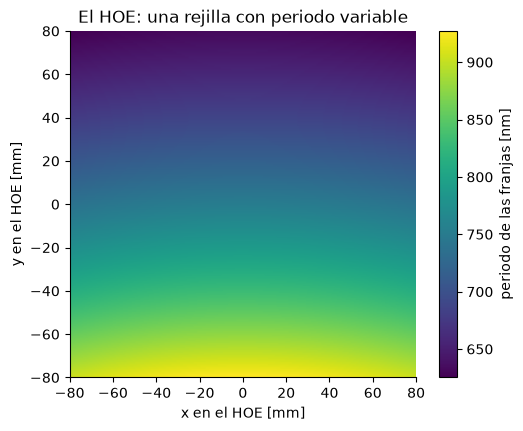

In [88]:
x = np.linspace(-80, 80, 201)
X, Y = np.meshgrid(x, x)
gx, gy, _ = hoe.get_gradient(X, Y)
periodo = 2 * np.pi / np.hypot(gx, gy) * 1e6          # mm -> nm

plt.figure(figsize=(6, 4.5))
plt.imshow(periodo, extent=[-80, 80, -80, 80], origin='lower', cmap='viridis')
plt.colorbar(label='periodo de las franjas [nm]')
plt.xlabel('x en el HOE [mm]'); plt.ylabel('y en el HOE [mm]')
plt.title('El HOE: una rejilla con periodo variable')
plt.show()

## 3. El arreglo en Optiland

### El truco: trazar del ojo al proyector
La pantalla del proyector tiene que estar **perpendicular a su eje**, o sea inclinada 45°. Optiland no deja inclinar el objeto (la superficie 0) cuando está fuera del eje, pero **sí la última superficie**. Como la luz es reversible (el camino proyector → ojo es el mismo que ojo → proyector), trazamos **al revés**, como una cámara que mira desde el ojo:

```
 superficie:  0          1             2        3       4        5        6           7
             (∞) ──► OJO (pupila ──► vidrio ─► PVB ─► HOE ─► PVB ─► vidrio ─► PANTALLA DEL
          "a dónde    + cristalino)                 (refleja)                 PROYECTOR
            mira"                                                             (inclinada 45°)
```

| Superficie | Qué es | Lo nuevo |
|---|---|---|
| 0 | hacia dónde mira el conductor | campos en **ángulo** = dirección de la mirada |
| 1 | ojo: pupila de 4 mm + cristalino ideal | `is_stop=True` y `surface_type='paraxial'`. Al revés, su lente hace converger los rayos al punto a 2 m que el ojo enfoca |
| 2–3 | aire → vidrio → PVB | `material=` es lo que hay **después** |
| 4 | **HOE** | `phase_profile=hoe` y `material='mirror'`. "Mirror" solo significa que **la luz regresa**; la dirección la decide la fase |
| 5–6 | PVB → vidrio → aire, de regreso | grosores **negativos**: después de reflejarse, la luz va hacia −z |
| 7 | pantalla del proyector | `dy` la baja 283 mm y `rx = −45°` la inclina |

In [89]:
P_R = np.array([0.0, -D_PROY * np.sin(A), -D_PROY * np.cos(A)])      # proyector respecto al HOE


def crear_hud():
    hud = Optic(name='HUD: del ojo al proyector')
    hud.surfaces.add(index=0, thickness=np.inf, comment='hacia donde mira')
    hud.surfaces.add(index=1, surface_type='paraxial', f=ENFOQUE, is_stop=True,
                     thickness=D_OJO - T_VIDRIO - T_PVB / 2, comment='ojo')
    hud.surfaces.add(index=2, thickness=T_VIDRIO, material=VIDRIO, comment='aire -> vidrio')
    hud.surfaces.add(index=3, thickness=T_PVB / 2, material=PVB, comment='vidrio -> PVB')
    hud.surfaces.add(index=4, thickness=-T_PVB / 2, phase_profile=hoe, material='mirror', comment='HOE')
    hud.surfaces.add(index=5, thickness=-T_VIDRIO, material=VIDRIO, comment='PVB -> vidrio')
    hud.surfaces.add(index=6, thickness=P_R[2] + T_VIDRIO + T_PVB / 2, comment='vidrio -> aire')
    hud.surfaces.add(index=7, dy=P_R[1], rx=-A, comment='pantalla proyector')
    hud.set_aperture(aperture_type='EPD', value=PUPILA)
    hud.fields.set_type(field_type='angle')
    for ax_, ay_ in [(0, 0), (-15, -15), (15, -15), (-15, 15), (15, 15)]:    # hasta dónde puede mirar [°]
        hud.fields.add(x=ax_, y=ay_)
    hud.wavelengths.add(value=LAM, is_primary=True)
    return hud


hud = crear_hud()
hud.info()

╒════╤═══════════════╤════════════════════╤══════════╤═════════════╤════════════╤═════════╤═════════════════╕
│    │ Type          │ Comment            │   Radius │   Thickness │ Material   │   Conic │   Semi-aperture │
╞════╪═══════════════╪════════════════════╪══════════╪═════════════╪════════════╪═════════╪═════════════════╡
│  0 │ Planar        │ hacia donde mira   │      inf │     inf     │ Air        │       0 │           2     │
│  1 │ Stop - Planar │ ojo                │      inf │     796.62  │ Air        │       0 │           2     │
│  2 │ Planar        │ aire -> vidrio     │      inf │       3     │ 1.518      │       0 │         214.657 │
│  3 │ Planar        │ vidrio -> PVB      │      inf │       0.38  │ 1.479      │       0 │         215.185 │
│  4 │ Planar        │ HOE                │      inf │      -0.38  │ Mirror     │       0 │         215.253 │
│  5 │ Planar        │ PVB -> vidrio      │      inf │      -3     │ 1.518      │       0 │         215.322 │
│  6 │ Pla

El dibujo va de lado (y contra z). El ojo está en z = 0 y el HOE en z = 800. Los rayos llegan al HOE, "rebotan" y bajan a la pantalla del proyector.

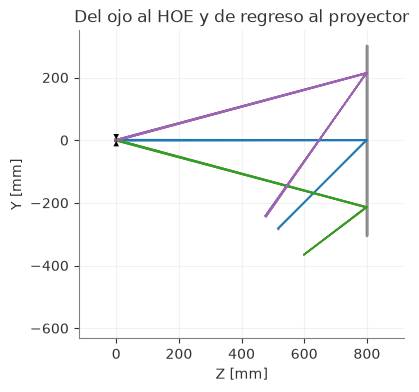

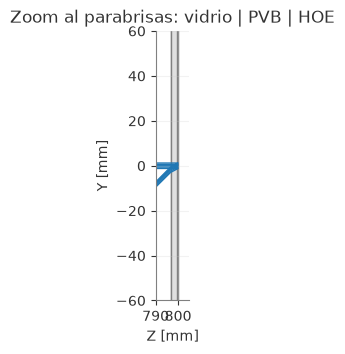

(<Figure size 800x350 with 1 Axes>,
 <Axes: title={'center': 'Zoom al parabrisas: vidrio | PVB | HOE'}, xlabel='Z [mm]', ylabel='Y [mm]'>)

In [90]:
hud.draw(num_rays=5, figsize=(12, 4), title='Del ojo al HOE y de regreso al proyector')
hud.draw(num_rays=5, figsize=(8, 3.5), xlim=(790, 805), ylim=(-60, 60), title='Zoom al parabrisas: vidrio | PVB | HOE')

### Seguir un rayo
`trazar` lanza rayos en una dirección de mirada (en grados) y regresa **dónde caen en la pantalla del proyector**, en coordenadas (u, v) en mm (u a lo ancho, v a lo alto). Ahí está la idea de todo: si mirando hacia (ax, ay) el rayo cae en el punto (u, v) de la pantalla, **el conductor ve en esa dirección ese píxel del proyector**.

In [91]:
def en_pantalla(h):
    """Pasa los puntos donde pegaron los rayos (x, y, z) a coordenadas (u, v) de la pantalla."""
    s = h.surfaces
    cs = s[-1].geometry.cs
    x, y, z = (be.to_numpy(a) for a in (s.x[-1], s.y[-1], s.z[-1]))
    u = x - float(cs.x)
    v = (y - float(cs.y)) * np.cos(A) - (z - float(cs.z)) * np.sin(A)
    return u, v


def trazar(h, ax, ay, Px=0.0, Py=0.0):
    """El conductor mira hacia (ax, ay) grados; los rayos pasan por el punto (Px, Py) de su pupila."""
    F = h.fields.max_field                         # Optiland quiere los campos normalizados (entre -1 y 1)
    h.trace_generic(Hx=np.asarray(ax) / F, Hy=np.asarray(ay) / F, Px=Px, Py=Py, wavelength=LAM)
    return en_pantalla(h)


# mirando al frente, por el centro y por la orilla de arriba y de abajo de la pupila
u, v = trazar(hud, 0, 0, Px=0, Py=np.array([-1.0, 0.0, 1.0]))
print('mirando al frente, los rayos caen en v =', np.round(v, 2), 'mm de la pantalla')

mirando al frente, los rayos caen en v = [1.96 1.13 0.28] mm de la pantalla


Los tres rayos salen de **la misma dirección de mirada**, pero caen en **tres puntos distintos** de la pantalla. Si el HOE fuera perfecto caerían en el mismo punto. Esa diferencia es la que va a hacer que la imagen se vea **borrosa**.

## 4. La imagen de prueba en el proyector

Se carga la imagen de la carpeta y se le da un **tamaño físico**: la pantalla del proyector mide `ANCHO_PANTALLA` mm de ancho.

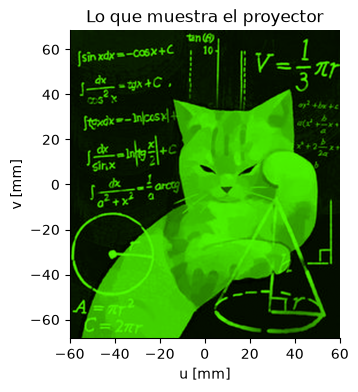

In [92]:
im = Image.open(IMAGEN).convert('L')                    # escala de grises
ancho_px = 500
foto = np.asarray(im.resize((ancho_px, round(ancho_px * im.size[1] / im.size[0])), Image.LANCZOS)) / 255.0

SEMI_U = ANCHO_PANTALLA / 2                             # media anchura [mm]
SEMI_V = SEMI_U * foto.shape[0] / foto.shape[1]         # media altura, respetando la proporción

plt.figure(figsize=(10, 4))
plt.imshow(foto, cmap=MAPA_LAM, extent=[-SEMI_U, SEMI_U, -SEMI_V, SEMI_V])
plt.xlabel('u [mm]'); plt.ylabel('v [mm]'); plt.title('Lo que muestra el proyector')
plt.show()

## 5. Lo que ve el conductor

Es la Lección 1.6 (la foto a través de la lente), pero **al revés**:
1. Se divide lo que ve el conductor en píxeles; cada píxel es una **dirección de mirada** (ax, ay).
2. Para cada dirección se lanzan `n` rayos por puntos **al azar de la pupila**.
3. `trazar` dice en qué punto (u, v) de la pantalla cae cada rayo, y se lee el brillo de la foto ahí.
4. Se **promedia** sobre la pupila. Si los rayos de un píxel caen en lugares distintos de la foto, ese píxel mezcla brillos: **se ve borroso**.

Para saber qué tan lejos mirar, primero se mide cuántos mm de pantalla hay por cada grado de mirada.

1° de mirada = 11.6 mm de pantalla a lo ancho y 7.6 mm a lo alto
la imagen ocupa unos 10.3° x 17.9° de la vista del conductor


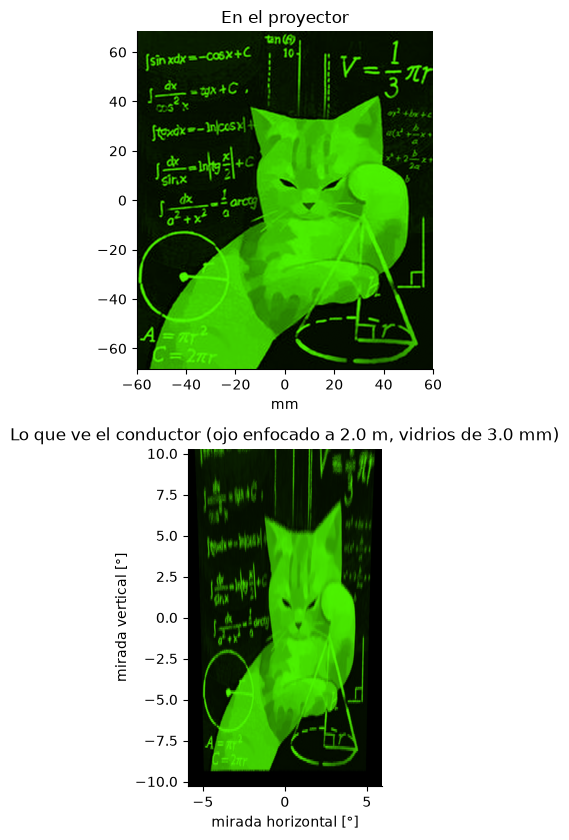

In [93]:
u1, _ = trazar(hud, 1, 0)                       # mirar 1° a la derecha
_, v1 = trazar(hud, 0, 1)                       # mirar 1° arriba
MIRA_X = 1.15 * SEMI_U / abs(u1[0])             # hasta dónde mirar para ver toda la foto (+15 %)
MIRA_Y = 1.15 * SEMI_V / abs(v1[0])
print(f'1° de mirada = {u1[0]:.1f} mm de pantalla a lo ancho y {v1[0]:.1f} mm a lo alto')
print(f'la imagen ocupa unos {2 * MIRA_X / 1.15:.1f}° x {2 * MIRA_Y / 1.15:.1f}° de la vista del conductor')


def lo_que_ve(h, px=(480, 200), n=16, lote=300_000):
    """Imagen (alto, ancho) que percibe el conductor."""
    ax = np.linspace(-MIRA_X, MIRA_X, px[0])
    ay = np.linspace(MIRA_Y, -MIRA_Y, px[1])               # de arriba hacia abajo
    AX, AY = np.meshgrid(ax, ay)
    AX, AY = AX.ravel(), AY.ravel()
    total = np.zeros(AX.size)
    rng = np.random.default_rng(0)
    for i in range(0, AX.size * n, lote):                   # por lotes, para no llenar la memoria
        idx = np.arange(i, min(i + lote, AX.size * n)) // n    # a qué píxel pertenece cada rayo
        r, t = np.sqrt(rng.random(idx.size)), 2 * np.pi * rng.random(idx.size)
        u, v = trazar(h, AX[idx], AY[idx], r * np.cos(t), r * np.sin(t))
        col = (u + SEMI_U) / (2 * SEMI_U) * (foto.shape[1] - 1)    # u -> columna de la foto
        fil = (SEMI_V - v) / (2 * SEMI_V) * (foto.shape[0] - 1)    # v -> fila (fila 0 = arriba)
        brillo = map_coordinates(foto, [np.nan_to_num(fil, nan=-9), np.nan_to_num(col, nan=-9)],
                                 order=1, cval=0.0)                # fuera de la foto = negro
        total += np.bincount(idx, weights=brillo, minlength=AX.size)
    return total.reshape(px[1], px[0]) / n


vista = lo_que_ve(hud)

fig, axs = plt.subplots(2, 1, figsize=(10, 8.5))
axs[0].imshow(foto, cmap=MAPA_LAM, extent=[-SEMI_U, SEMI_U, -SEMI_V, SEMI_V])
axs[0].set_title('En el proyector'); axs[0].set_xlabel('mm')
axs[1].imshow(vista, cmap=MAPA_LAM, vmin=0, vmax=1, extent=[-MIRA_X, MIRA_X, -MIRA_Y, MIRA_Y])
axs[1].set_title(f'Lo que ve el conductor (ojo enfocado a {ENFOQUE / 1000:.1f} m, vidrios de {T_VIDRIO} mm)')
axs[1].set_xlabel('mirada horizontal [°]'); axs[1].set_ylabel('mirada vertical [°]')
plt.tight_layout(); plt.show()

**¿Qué se ve?**
- La imagen **sí se forma**: el HOE hace de lente y el conductor la ve flotando, de unos 10° de ancho.
- Sale **estirada a lo alto** y no es un rectángulo exacto. El HOE no amplifica igual en las dos direcciones: 1° de mirada son 11.6 mm de pantalla a lo ancho, pero solo 7.6 mm a lo alto.
- **Las letras chicas se ven borrosas**, corridas en vertical. Es lo que vimos en la sección 3: los rayos de una misma mirada no caen en el mismo punto.
- El **granulado** no es óptica: es por usar pocos rayos por píxel (`n=16`). Si subes `n`, se quita, pero tarda más.

¿Por qué? Usamos el HOE **simple** (lente + rejilla) y lo leemos a **45°**. Una lente usada tan inclinada ya no enfoca igual en vertical que en horizontal. Eso queda para revisarlo después.

**Prueba tú** (cambia los parámetros de la sección 1 y vuelve a correr todo):
- `ENFOQUE = 1500` o `3000`: ¿la imagen mejora o empeora? ¿A qué distancia está en realidad?
- `PUPILA = 2.0` (día soleado) vs. `6.0` (de noche): ¿cuál se ve más nítida?
- `T_VIDRIO = 0.0`: ¿cambia algo el vidrio?
- `LAM = 0.540`: el HOE se hizo para 532 nm. ¿Qué pasa con otro color?
- `IMAGEN = 'hoe_2_reconstruccion.png'`.

## 6. Vista 3D

La escena de Optiland, más el **parabrisas** (vidrio, PVB, vidrio) y la **pantalla del proyector con la imagen**. Los rayos van del ojo al HOE y bajan a la pantalla.
- `escena3D(ventana=True)` abre una ventana para girar con el mouse; la celda queda corriendo hasta que la cierres.
- `escena3D(ventana=False)` la pone como imagen dentro del notebook.

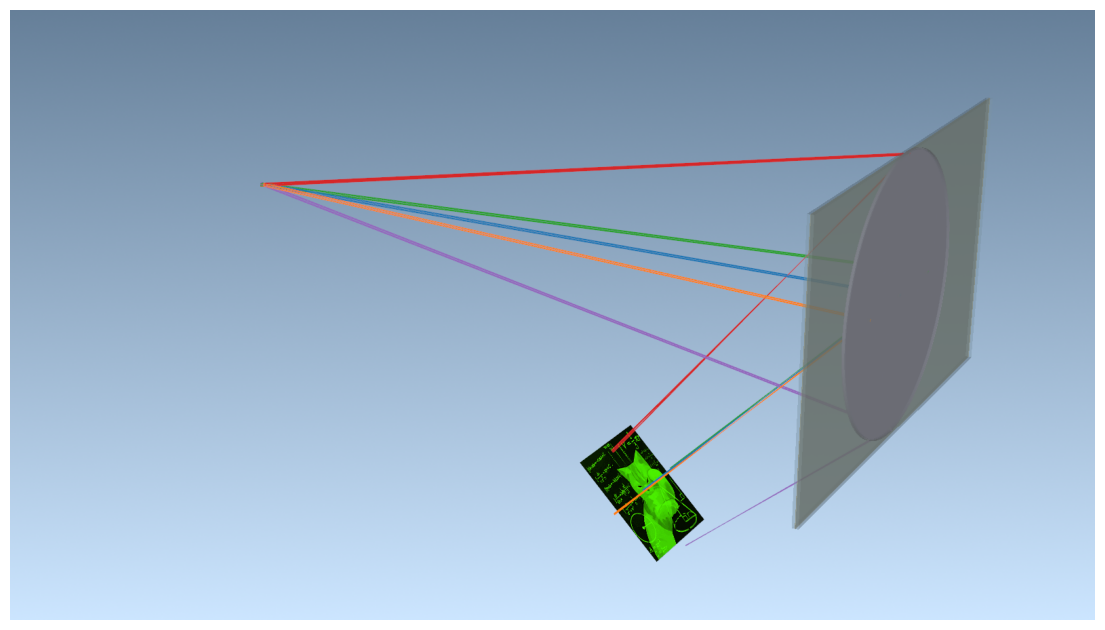

In [94]:
import vtk
from vtk.util.numpy_support import numpy_to_vtk, vtk_to_numpy
from optiland.visualization import OpticViewer3D


def plano_con_imagen(img, centro, eje_u, eje_v, semi_u, semi_v):
    """Rectángulo en 3D con la imagen img (fila 0 = arriba) pegada como textura, del color de LAM."""
    a = np.clip(img[::-1], 0, 1)                                # VTK empieza por la fila de abajo
    rgb = (a[..., None] * COLOR_LAM * 255).astype(np.uint8)     # brillo × color de la luz
    datos = vtk.vtkImageData(); datos.SetDimensions(a.shape[1], a.shape[0], 1)
    datos.GetPointData().SetScalars(numpy_to_vtk(rgb.reshape(-1, 3), deep=True))
    tex = vtk.vtkTexture(); tex.SetInputData(datos); tex.InterpolateOn()
    plano = vtk.vtkPlaneSource()
    plano.SetOrigin(*(centro - semi_u * eje_u - semi_v * eje_v))
    plano.SetPoint1(*(centro + semi_u * eje_u - semi_v * eje_v))
    plano.SetPoint2(*(centro - semi_u * eje_u + semi_v * eje_v))
    m = vtk.vtkPolyDataMapper(); m.SetInputConnection(plano.GetOutputPort())
    actor = vtk.vtkActor(); actor.SetMapper(m); actor.SetTexture(tex)
    actor.GetProperty().LightingOff()
    return actor


def placa(z0, z1, color, opacidad, semi=(250, 150)):
    """Una capa del parabrisas, entre z0 y z1."""
    caja = vtk.vtkCubeSource()
    caja.SetBounds(-semi[0], semi[0], -semi[1], semi[1], min(z0, z1), max(z0, z1))
    m = vtk.vtkPolyDataMapper(); m.SetInputConnection(caja.GetOutputPort())
    actor = vtk.vtkActor(); actor.SetMapper(m)
    actor.GetProperty().SetColor(*color); actor.GetProperty().SetOpacity(opacidad)
    return actor


def escena3D(num_rays=8, ventana=True, azimut=60, elevacion=20, acercar=1.6, tam=(1600, 900)):
    h = crear_hud()
    v3 = OpticViewer3D(h)
    if not ventana:
        v3.ren_win.SetOffScreenRendering(1)
    inicio = v3.iren.Start; v3.iren.Start = lambda: None
    F = h.fields.max_field
    v3.view(fields=[(0, 0), (-MIRA_X / F, 0), (MIRA_X / F, 0), (0, MIRA_Y / F), (0, -MIRA_Y / F)],
            num_rays=num_rays, figsize=tam)
    ren = v3.ren_win.GetRenderers().GetFirstRenderer()
    ren.AddActor(placa(D_OJO - T_PVB / 2 - T_VIDRIO, D_OJO - T_PVB / 2, (0.75, 0.9, 1.0), 0.25))   # vidrio interior
    ren.AddActor(placa(D_OJO - T_PVB / 2, D_OJO + T_PVB / 2, (1.0, 0.95, 0.7), 0.35))             # PVB + HOE
    ren.AddActor(placa(D_OJO + T_PVB / 2, D_OJO + T_PVB / 2 + T_VIDRIO, (0.75, 0.9, 1.0), 0.25))   # vidrio exterior
    cs = h.surfaces[-1].geometry.cs
    centro = np.array([float(cs.x), float(cs.y), float(cs.z)])
    eje_u, eje_v = np.array([1.0, 0.0, 0.0]), np.array([0.0, np.cos(A), -np.sin(A)])
    ren.AddActor(plano_con_imagen(foto, centro, eje_u, eje_v, SEMI_U, SEMI_V))
    ren.ResetCamera()
    cam = ren.GetActiveCamera(); cam.Azimuth(azimut); cam.Elevation(elevacion); cam.Zoom(acercar)
    v3.ren_win.Render()
    if ventana:
        inicio()
    else:
        w = vtk.vtkWindowToImageFilter(); w.SetInput(v3.ren_win); w.Update()
        img = w.GetOutput(); nx, ny, _ = img.GetDimensions()
        pix = vtk_to_numpy(img.GetPointData().GetScalars()).reshape(ny, nx, -1)[::-1]
        plt.figure(figsize=(14, 8)); plt.imshow(pix); plt.axis('off'); plt.show()
    v3.ren_win.Finalize()


escena3D(ventana=False)      # imagen dentro del notebook
# escena3D(ventana=True)     # ventana para rotar y hacer zoom